# Projet 4 : Classifiez automatiquement des informations

## Analyse exploratoire des données (EDA)

### 1 - Chargement des librairies et du fichier

In [41]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sb
import numpy as np

In [ ]:
DATA_RAW = Path("../Data/Raw")

df_brut_eval = pd.read_csv(DATA_RAW / "extrait_eval.csv")

### 2 - Audit du dataset

dataset complet

In [43]:
df_brut_eval

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %
...,...,...,...,...,...,...,...,...,...,...
1465,3,4,2,4,3,3,E_2061,3,Non,17 %
1466,4,2,3,1,1,3,E_2062,3,Non,15 %
1467,2,4,2,2,2,3,E_2064,4,Oui,20 %
1468,4,2,2,2,4,2,E_2065,3,Non,14 %


Dimensions du dataset

In [44]:
df_brut_eval.shape

(1470, 10)

Nulls, et types de colonnes

In [45]:
df_brut_eval.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 10 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   satisfaction_employee_environnement        1470 non-null   int64 
 1   note_evaluation_precedente                 1470 non-null   int64 
 2   niveau_hierarchique_poste                  1470 non-null   int64 
 3   satisfaction_employee_nature_travail       1470 non-null   int64 
 4   satisfaction_employee_equipe               1470 non-null   int64 
 5   satisfaction_employee_equilibre_pro_perso  1470 non-null   int64 
 6   eval_number                                1470 non-null   object
 7   note_evaluation_actuelle                   1470 non-null   int64 
 8   heure_supplementaires                      1470 non-null   object
 9   augementation_salaire_precedente           1470 non-null   object
dtypes: int64(7), object(3)
memory usage:

Min, Max

In [46]:
df_brut_eval.describe(include='all')

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470,1470.000000,1470,1470
unique,NaN,NaN,NaN,NaN,NaN,NaN,1470,NaN,2,15
top,NaN,NaN,NaN,NaN,NaN,NaN,E_1,NaN,Non,11 %
freq,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,1054,210
mean,2.721769,2.729932,2.063946,2.728571,2.712245,2.761224,NaN,3.153741,NaN,NaN
std,1.093082,0.711561,1.106940,1.102846,1.081209,0.706476,NaN,0.360824,NaN,NaN
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,NaN,3.000000,NaN,NaN
25%,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,NaN,3.000000,NaN,NaN
50%,3.000000,3.000000,2.000000,3.000000,3.000000,3.000000,NaN,3.000000,NaN,NaN
75%,4.000000,3.000000,3.000000,4.000000,4.000000,3.000000,NaN,3.000000,NaN,NaN


Doubons sur tout le dataset

In [47]:
df_brut_eval.duplicated().value_counts()

False    1470
Name: count, dtype: int64

Doublons sur la colonne identifiante 

In [48]:
df_brut_eval.duplicated(subset=['eval_number']).value_counts()

False    1470
Name: count, dtype: int64

### 3 - Exploration des données

Distribution des employés faisant des heures supplémentaires

In [51]:
df_brut_eval['heure_supplementaires'].value_counts()

heure_supplementaires
Non    1054
Oui     416
Name: count, dtype: int64

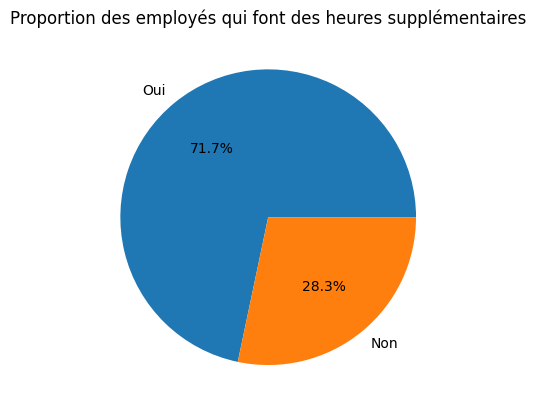

In [67]:
plt.pie(df_brut_eval['heure_supplementaires'].value_counts(), labels=df_brut_eval['heure_supplementaires'].unique(), autopct="%1.1f%%")
plt.title('Proportion des employés qui font des heures supplémentaires')
plt.show()

Proportion des employés par niveau hiérarchique

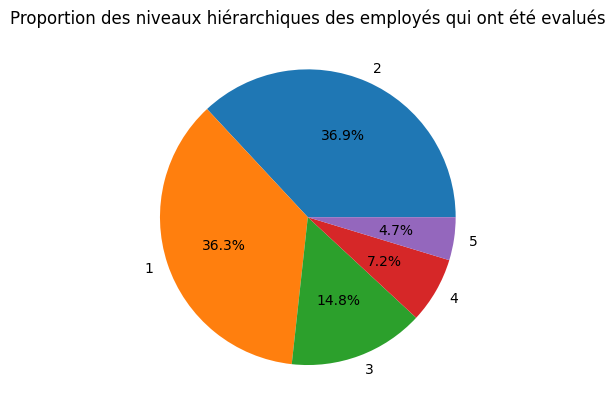

In [68]:
plt.pie(df_brut_eval['niveau_hierarchique_poste'].value_counts(),labels=df_brut_eval['niveau_hierarchique_poste'].unique(), autopct="%1.1f%%")
plt.title('Proportion des niveaux hiérarchiques des employés qui ont été evalués')
plt.show()

Distribution des augmentations de salaire

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
 [Text(0, 0, '11 %'),
  Text(1, 0, '23 %'),
  Text(2, 0, '15 %'),
  Text(3, 0, '12 %'),
  Text(4, 0, '13 %'),
  Text(5, 0, '20 %'),
  Text(6, 0, '22 %'),
  Text(7, 0, '21 %'),
  Text(8, 0, '17 %'),
  Text(9, 0, '14 %'),
  Text(10, 0, '16 %'),
  Text(11, 0, '18 %'),
  Text(12, 0, '19 %'),
  Text(13, 0, '24 %'),
  Text(14, 0, '25 %')])

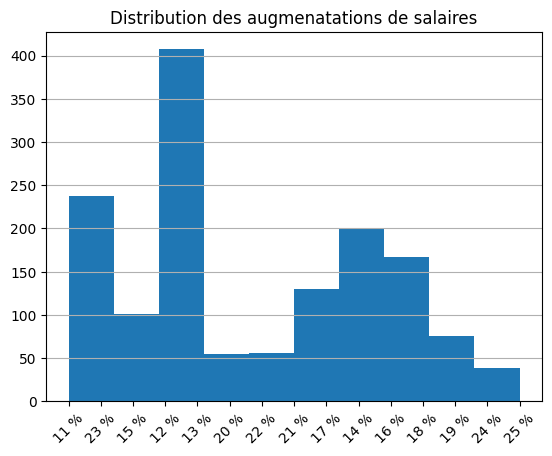

In [71]:
plt.hist(df_brut_eval['augementation_salaire_precedente'])
plt.title("Distribution des augmenatations de salaires")
plt.grid(axis='y')
plt.xticks(rotation=45)

Distribution des satisfactions equilibre (vie pro <> vie perso)

([<matplotlib.axis.XTick at 0x12e47a310>,
 [Text(1, 0, '1'), Text(2, 0, '2'), Text(3, 0, '3'), Text(4, 0, '4')])

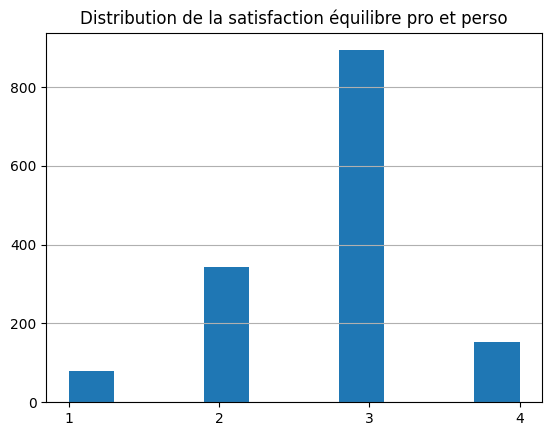

In [76]:
plt.hist(df_brut_eval['satisfaction_employee_equilibre_pro_perso'])
plt.title("Distribution de la satisfaction équilibre pro et perso")
plt.grid(axis='y')
plt.xticks([1, 2, 3, 4]) 